# Исследование импульса Лоренца и сравнение с синусоидой
Рабочая копия расчёта. Исходные ноутбуки и модули не редактируются.
Ячейки формирования сигналов и диаграмм перенесены из `notebook.ipynb`,
схема эксперимента по SNR — из `report.ipynb`.
Дополнения: сохранение рисунков, аналитические проверки, независимая
инициализация генератора для каждого метода и статистики ошибок.
Используются текущие параметры `py_files/config.py`, включая τ = 0,05 с.


In [1]:
from pathlib import Path
import sys, os, json, csv
ROOT = Path.cwd()
if not (ROOT / 'py_files').exists():
    ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'reports/lorentz_study'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
import matplotlib
matplotlib.use('Agg')

from IPython.display import Image


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.config as cfg

from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       get_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       get_direction_matrix, 
                       get_est_phi,
                       get_cap_values,
                       calculate_freq_spectr)

config_parametrs = cfg.init_rng()

In [3]:
sin_signal = get_sin_signal(config_parametrs)
pulse_signal = get_impulse_signal(config_parametrs)
en_signal = calculate_energy(pulse_signal, config_parametrs["time_vector"])

freq_signal = calculate_freq_spectr(pulse_signal, cfg.FS)

## Воспроизведение графиков исходного ноутбука

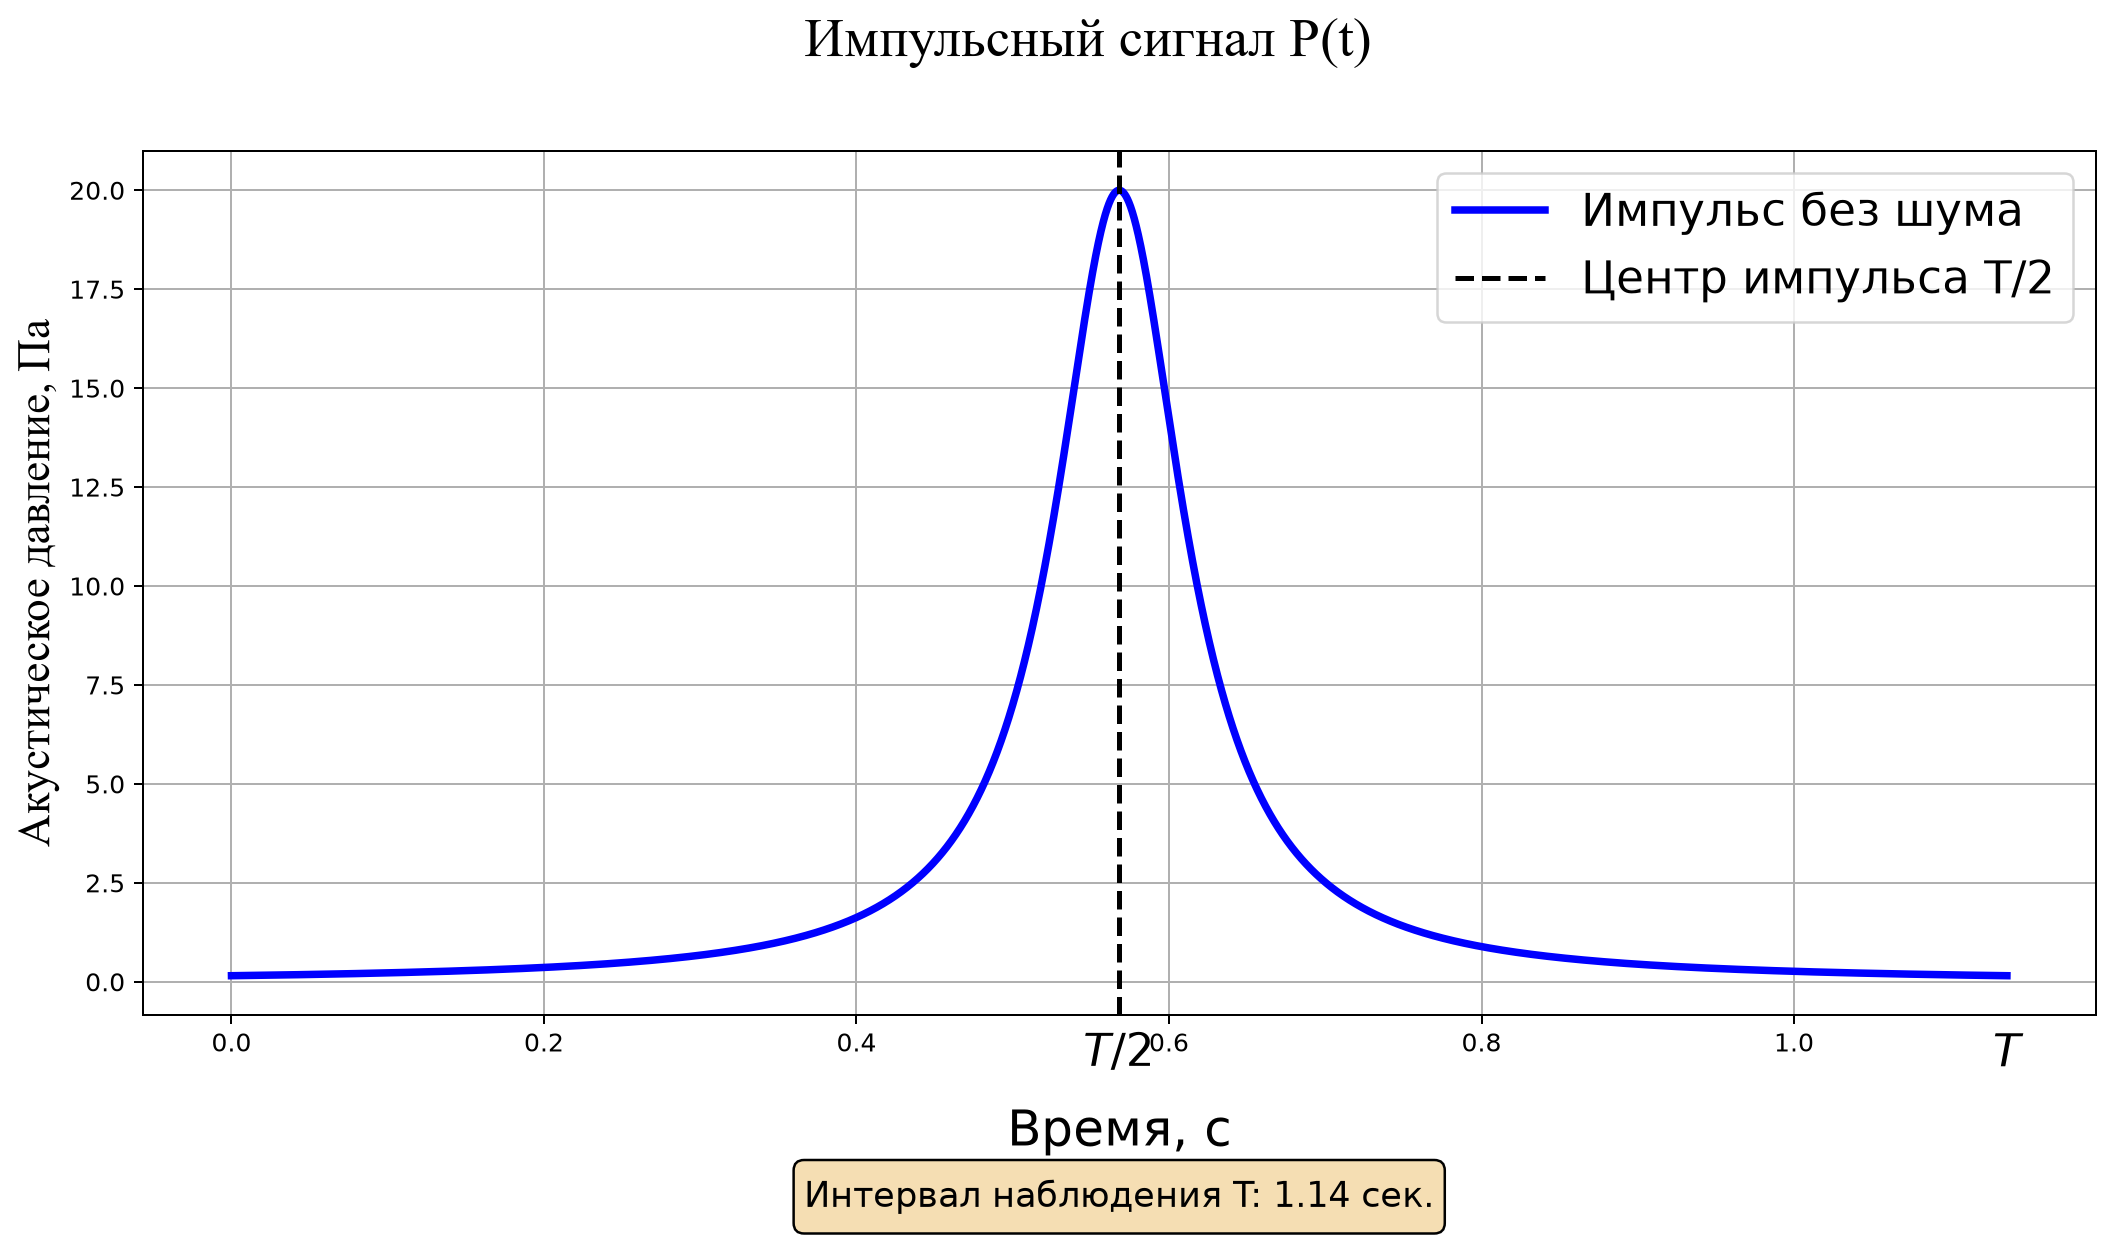

In [4]:


# Построение графика

fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="blue", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    "Импульсный сигнал P(t)",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)

ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (

    f"Интервал наблюдения T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)

fig.savefig(FIG / '01_pulse.png', dpi=180, bbox_inches='tight')
from IPython.display import display
display(Image(filename=str(FIG/'01_pulse.png')))
plt.close(fig)

C:\Users\Admin\AppData\Local\Temp\ipykernel_2804\1928006181.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right", fontsize=18)


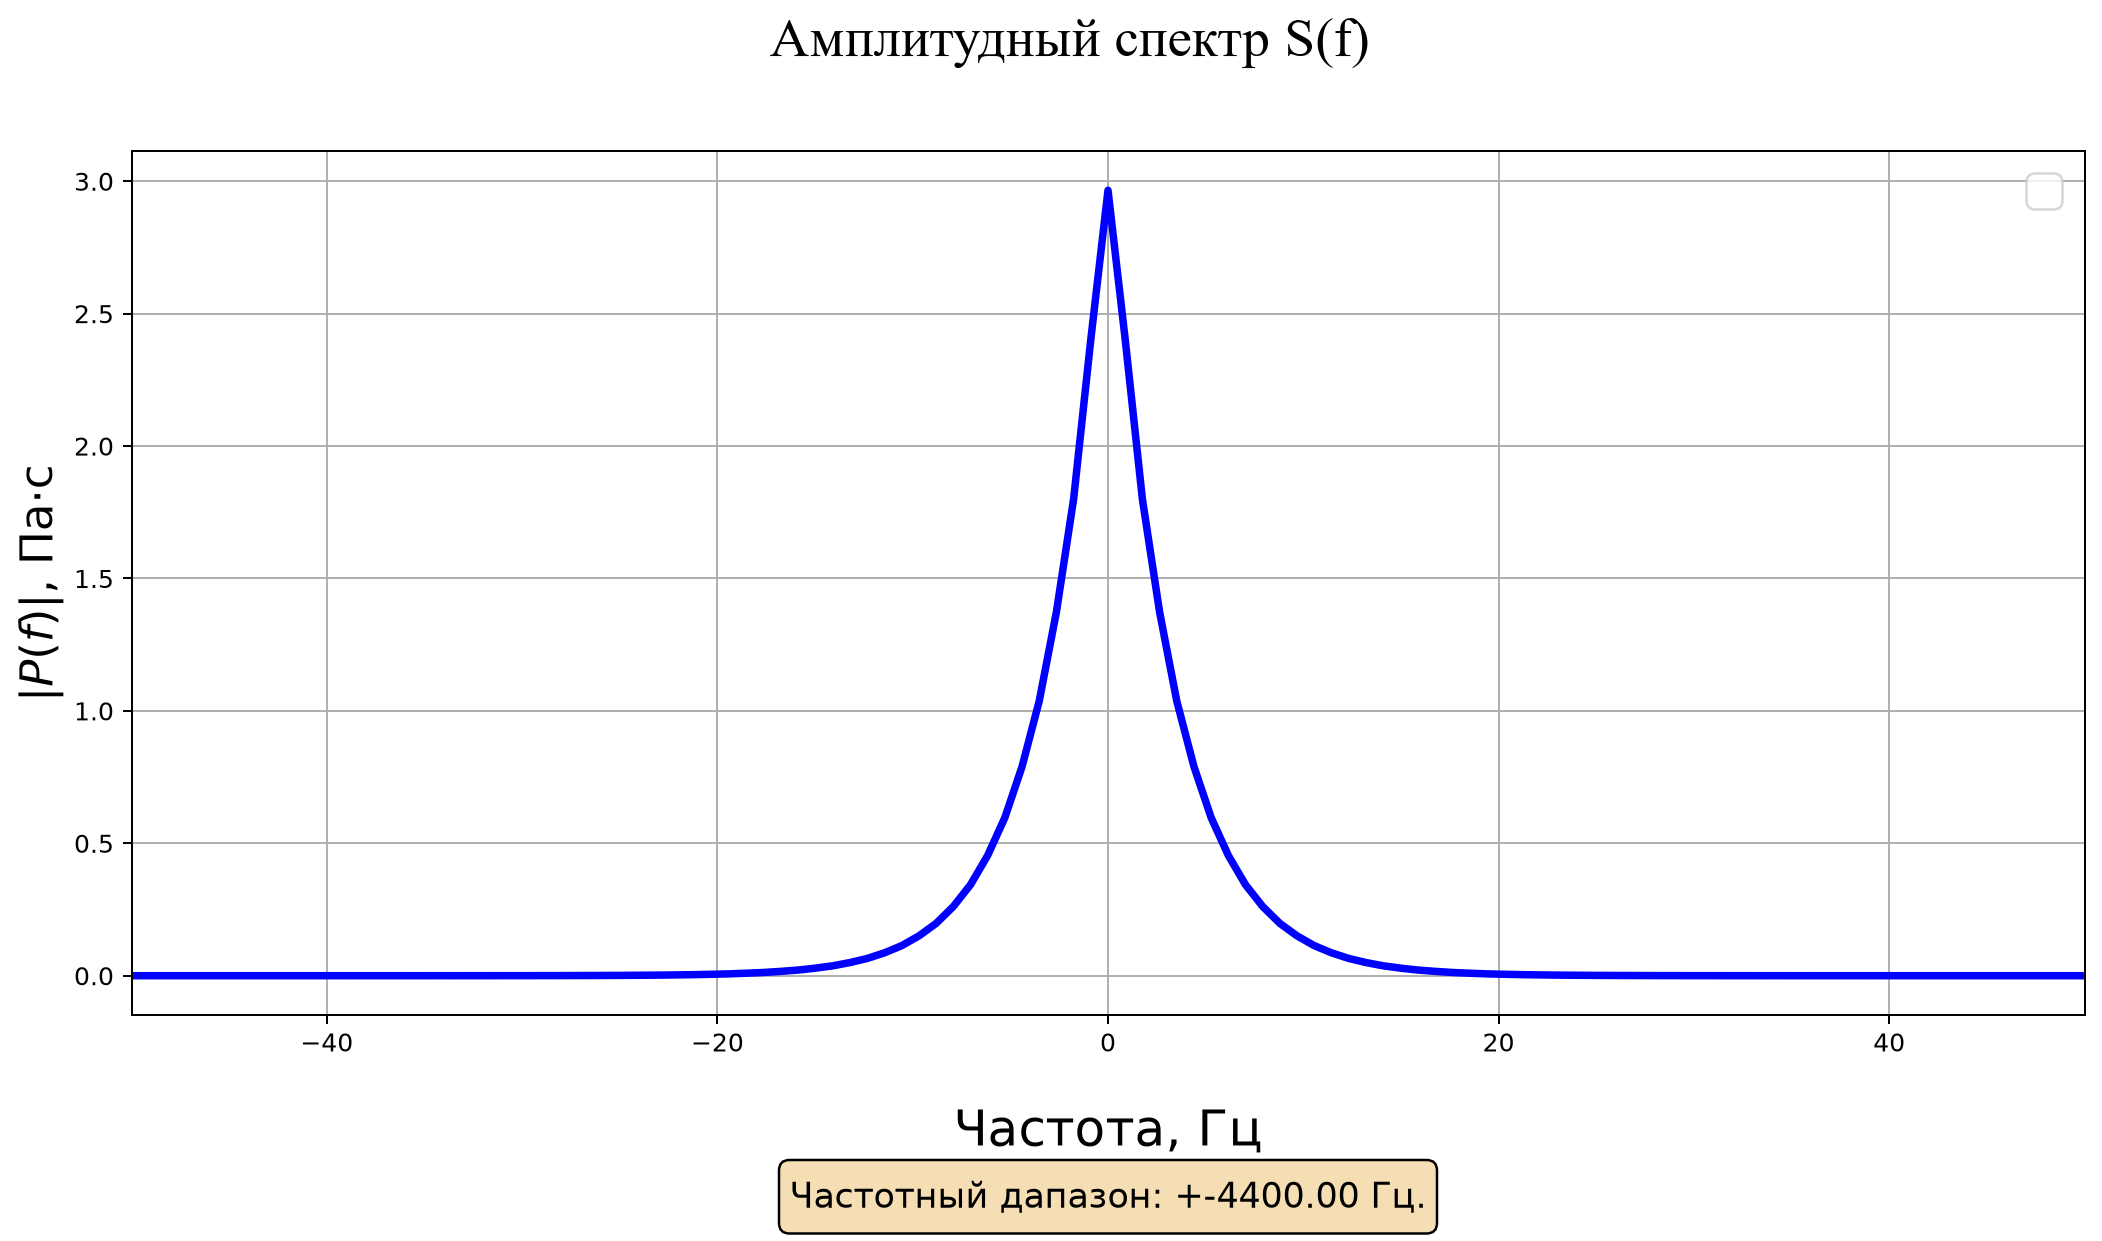

In [5]:


# Построение графика

fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, freq_signal,
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Частота, Гц", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|P(f)|$, Па·с", fontsize=18)
fig.suptitle(
    "Амплитудный спектр S(f) ",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени



ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (

    f"Частотный дапазон: +-{config_parametrs['fs']/2:.2f} Гц."
    
)
ax.set_xlim(-50,50)
ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)

fig.savefig(FIG / '02_fft_original.png', dpi=180, bbox_inches='tight')
from IPython.display import display
display(Image(filename=str(FIG/'02_fft_original.png')))
plt.close(fig)

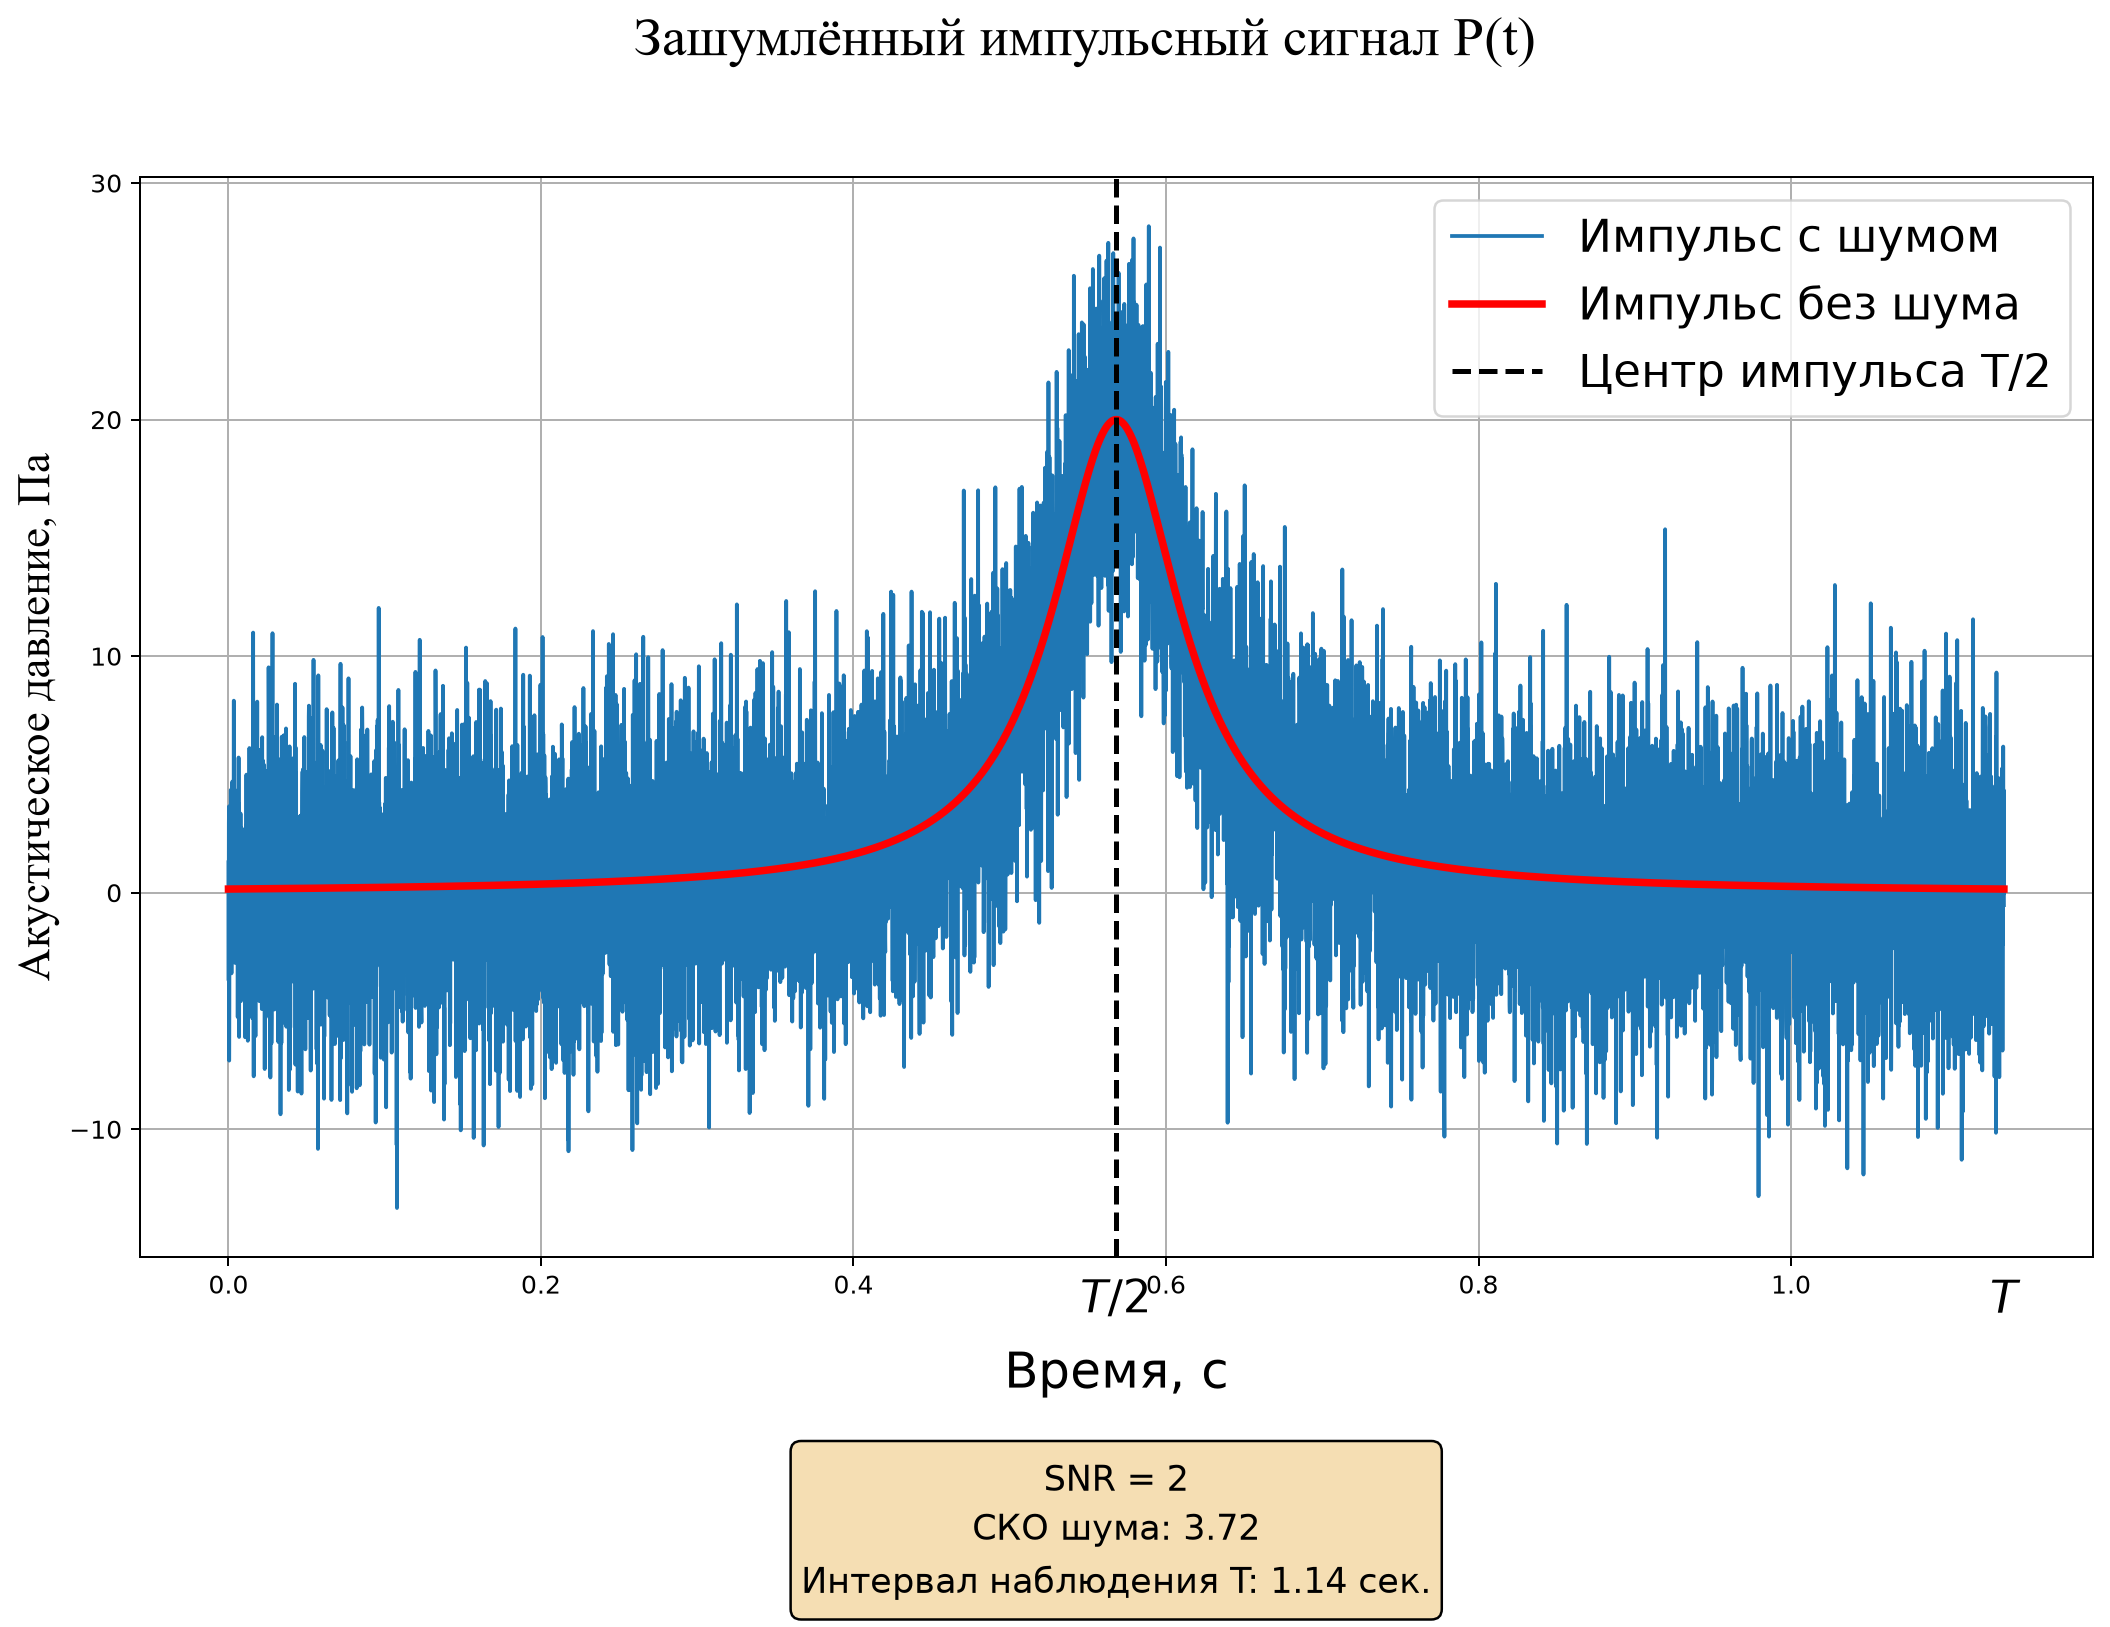

In [6]:
# Построение графика

noise = get_noise(config_parametrs, np.random.default_rng(42),en_signal)
noise_level = calculate_noise_level(en_signal, config_parametrs["snr"], config_parametrs["duration_all"])

noise_signal = pulse_signal + noise
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(cfg.TIME_VECTOR, noise_signal, label="Импульс с шумом")
ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="red", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    "Зашумлённый импульсный сигнал P(t)",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)

ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (
    f"SNR = {cfg.SNR}\n"
    f"СКО шума: {noise_level:.2f}\n"
    f"Интервал наблюдения T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)

fig.savefig(FIG / '03_noise.png', dpi=180, bbox_inches='tight')
from IPython.display import display
display(Image(filename=str(FIG/'03_noise.png')))
plt.close(fig)

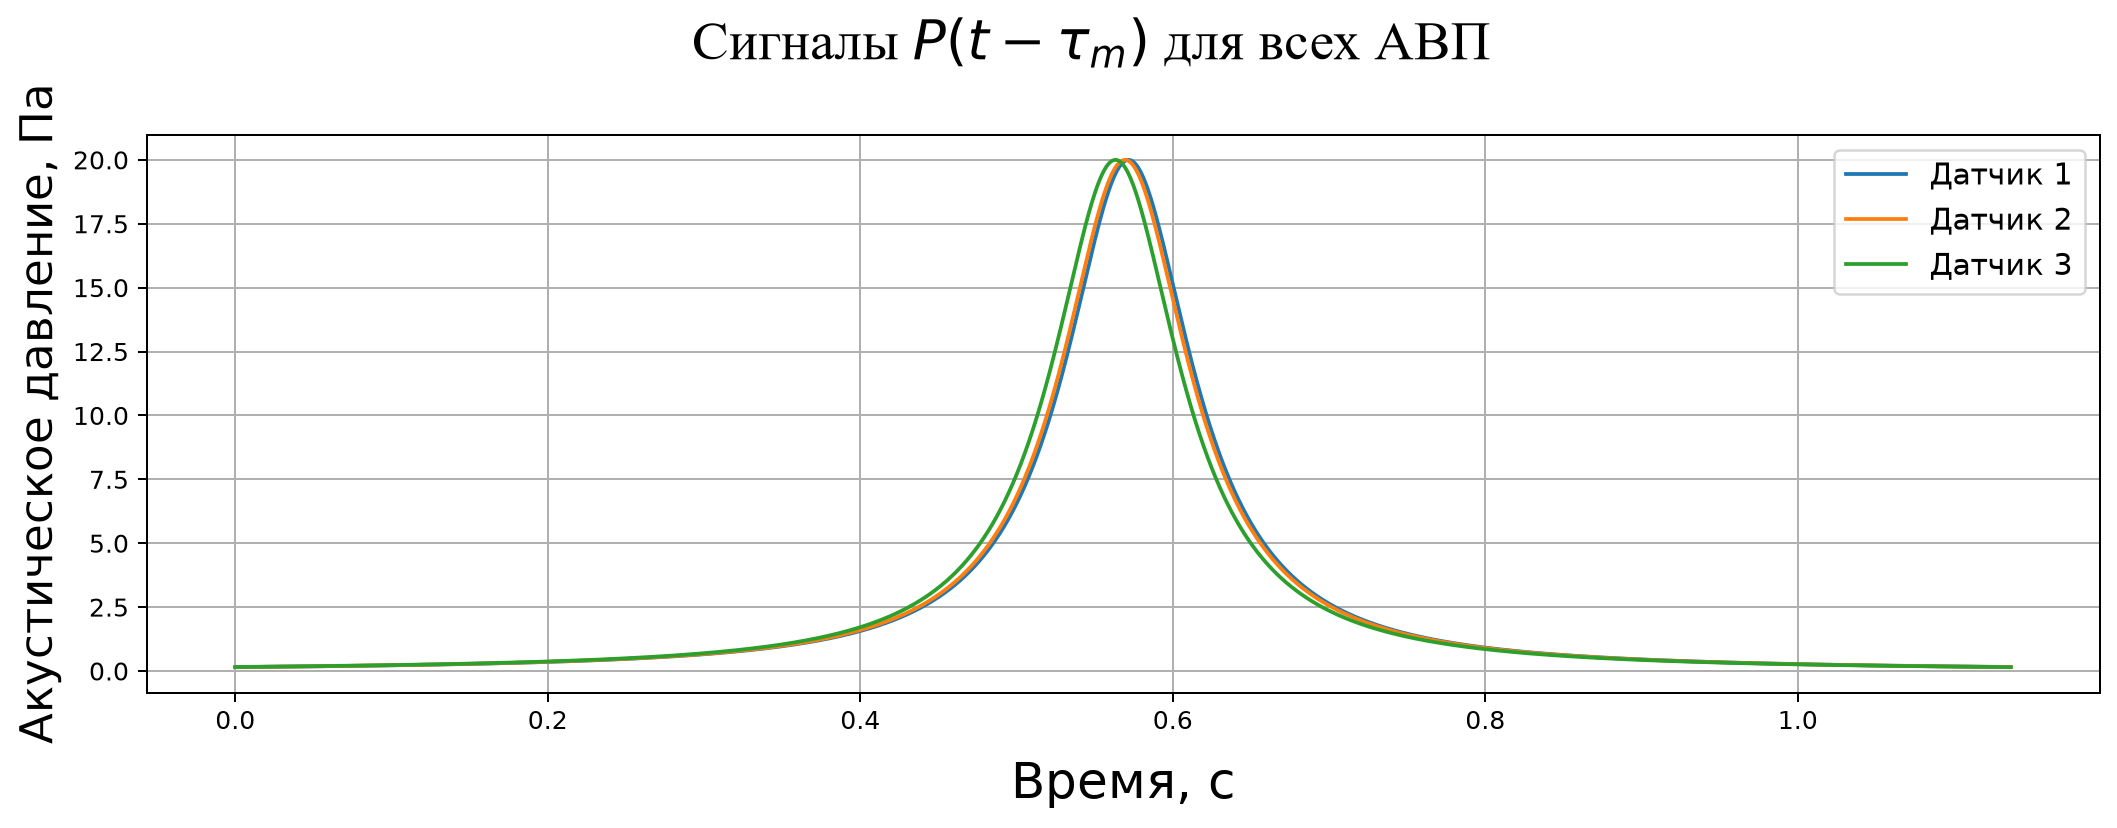

In [7]:
tau_array = get_tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()

fig, ax = plt.subplots(1, 1, figsize=(14, 5))
fig.subplots_adjust(top=0.80, bottom=0.18)

# Сигнал на каждом датчике
for idx, tau in enumerate(tau_array):
    params_vector_copy["time_vector"] = config_parametrs["time_vector"] - tau
    signal = get_impulse_signal(params_vector_copy)

    ax.plot(
        config_parametrs["time_vector"], signal,
        label=f"Датчик {idx + 1}"
    )

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=10, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18)
fig.suptitle(
    r"Сигналы $P(t-\tau_m)$ для всех АВП",
    y=0.90, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=12)

fig.savefig(FIG / '04_sensors.png', dpi=180, bbox_inches='tight')
from IPython.display import display
display(Image(filename=str(FIG/'04_sensors.png')))
plt.close(fig)

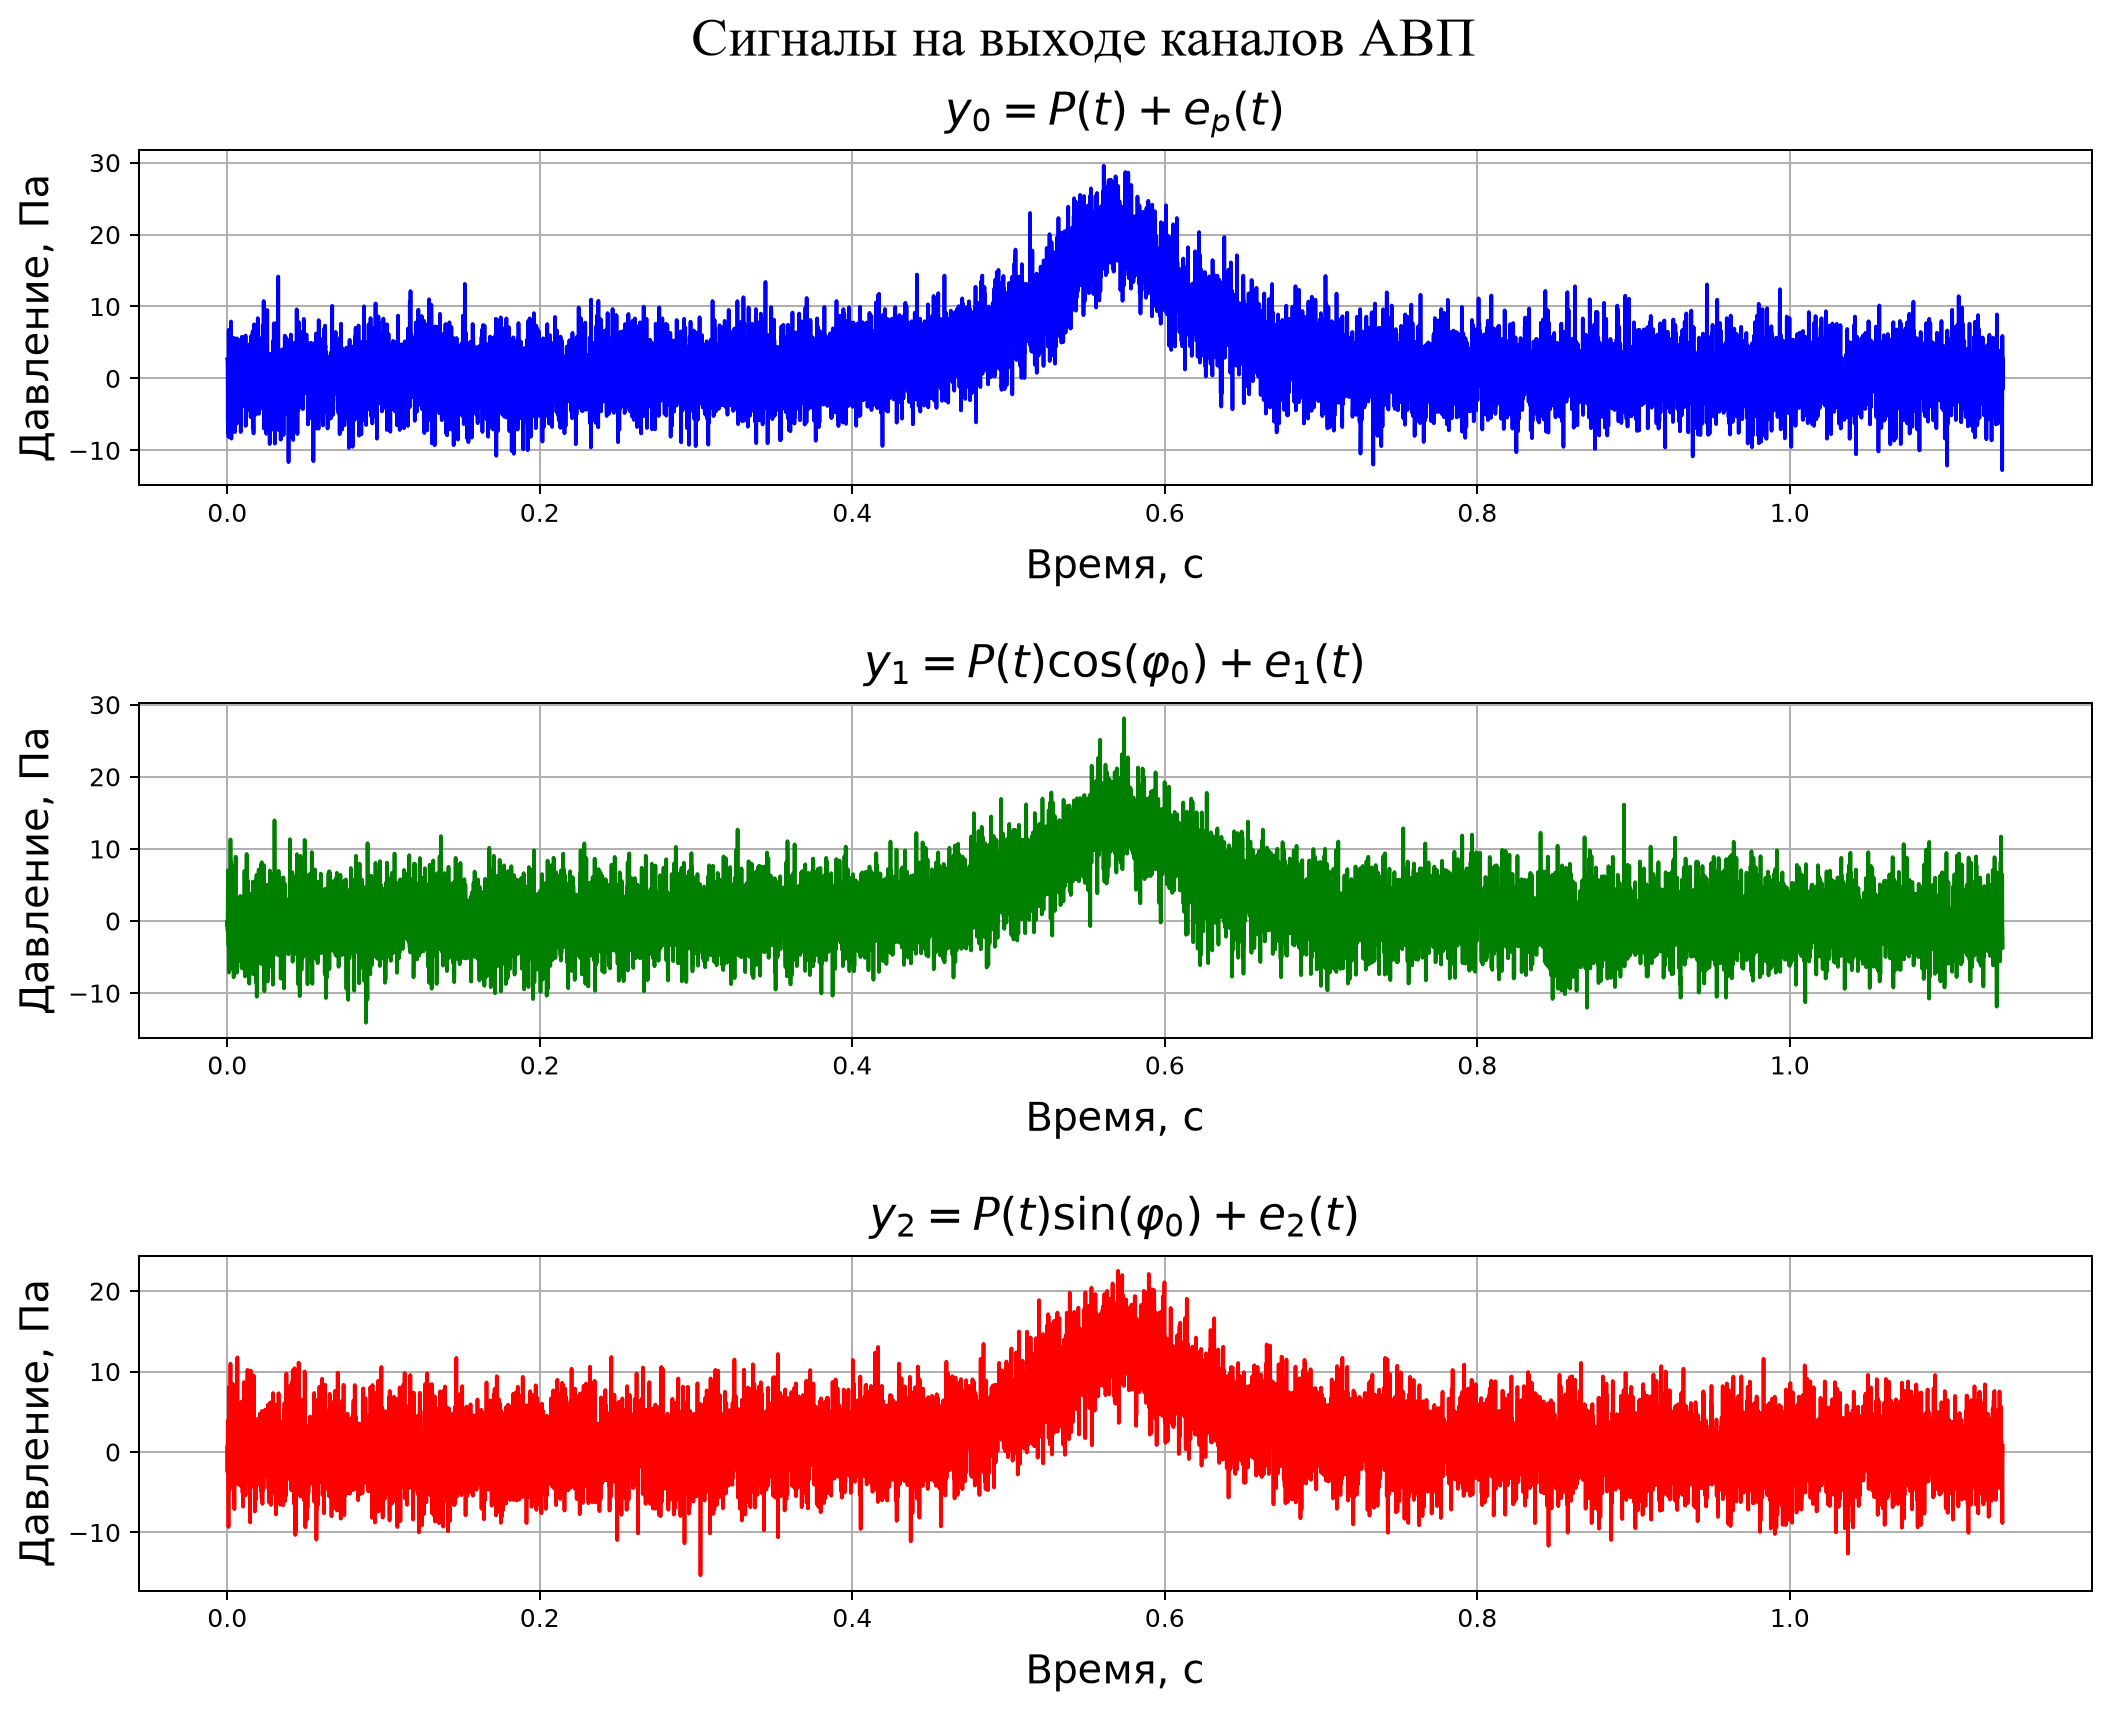

In [8]:
cfg.init_rng()
signals = get_avp_signals(pulse_signal, config_parametrs, en_signal)

fig, axs = plt.subplots(3, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.88, bottom=0.08, hspace=0.65)

fig.suptitle(
    "Сигналы на выходе каналов АВП",
    y=0.94, va="center",
    fontfamily="Times New Roman", fontsize=22
)

colors = ("blue", "green", "red")
titles = (
    r"$y_0 = P(t) + e_p(t)$",
    r"$y_1 = P(t)\cos(\varphi_0) + e_1(t)$",
    r"$y_2 = P(t)\sin(\varphi_0) + e_2(t)$"
)

for ax, y, title, color in zip(axs, signals.values(), titles, colors):
    ax.plot(cfg.TIME_VECTOR, y, color=color)
    ax.set_xlabel("Время, с", labelpad=8, fontsize=16)
    ax.set_ylabel("Давление, Па", fontsize=16)
    ax.set_title(title, pad=10, fontsize=18)
    ax.grid(True)

fig.savefig(FIG / '05_channels.png', dpi=180, bbox_inches='tight')
from IPython.display import display
display(Image(filename=str(FIG/'05_channels.png')))
plt.close(fig)

In [9]:
channel_matrix = get_channel_matrix(config_parametrs, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, cfg.N)
dir_matrix = get_direction_matrix(cfg.PHI_VECTOR, cfg.M)
E_bar = get_barlet_values(W,dir_matrix)
E_cap = get_cap_values(W, dir_matrix)


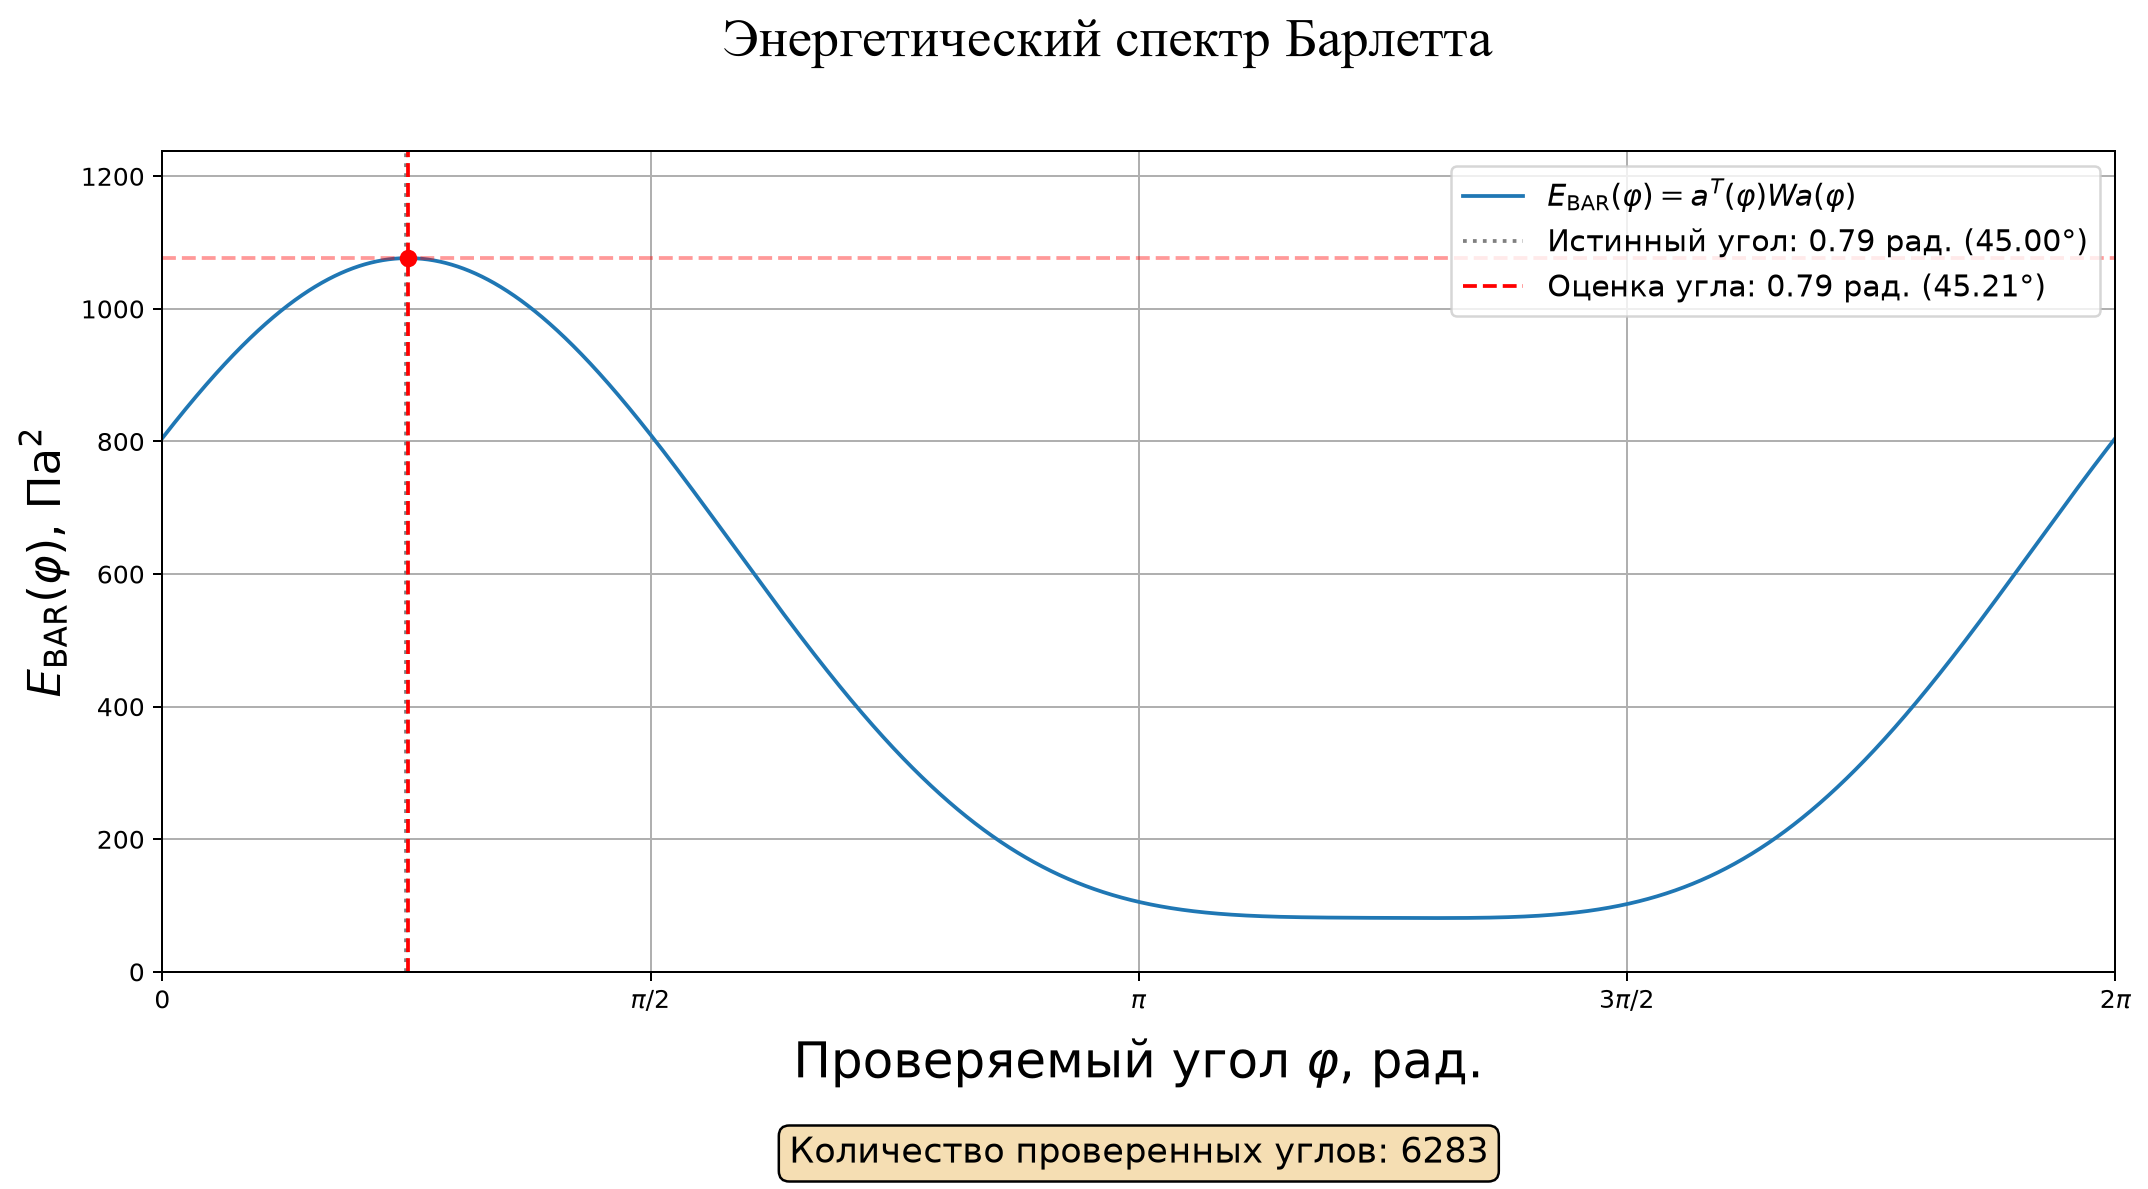

In [10]:

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_bar)
E_max = max(E_bar)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Бартлетта и отметки углов
ax.plot(
    phi_vector, E_bar,
    label=r"$E_{\mathrm{BAR}}(\varphi)=a^T(\varphi)W a(\varphi)$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.2f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.2f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Энергетический спектр Барлетта",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)

fig.savefig(FIG / '06_bartlett_original.png', dpi=180, bbox_inches='tight')
display(Image(filename=str(FIG/'06_bartlett_original.png')))
plt.close(fig)

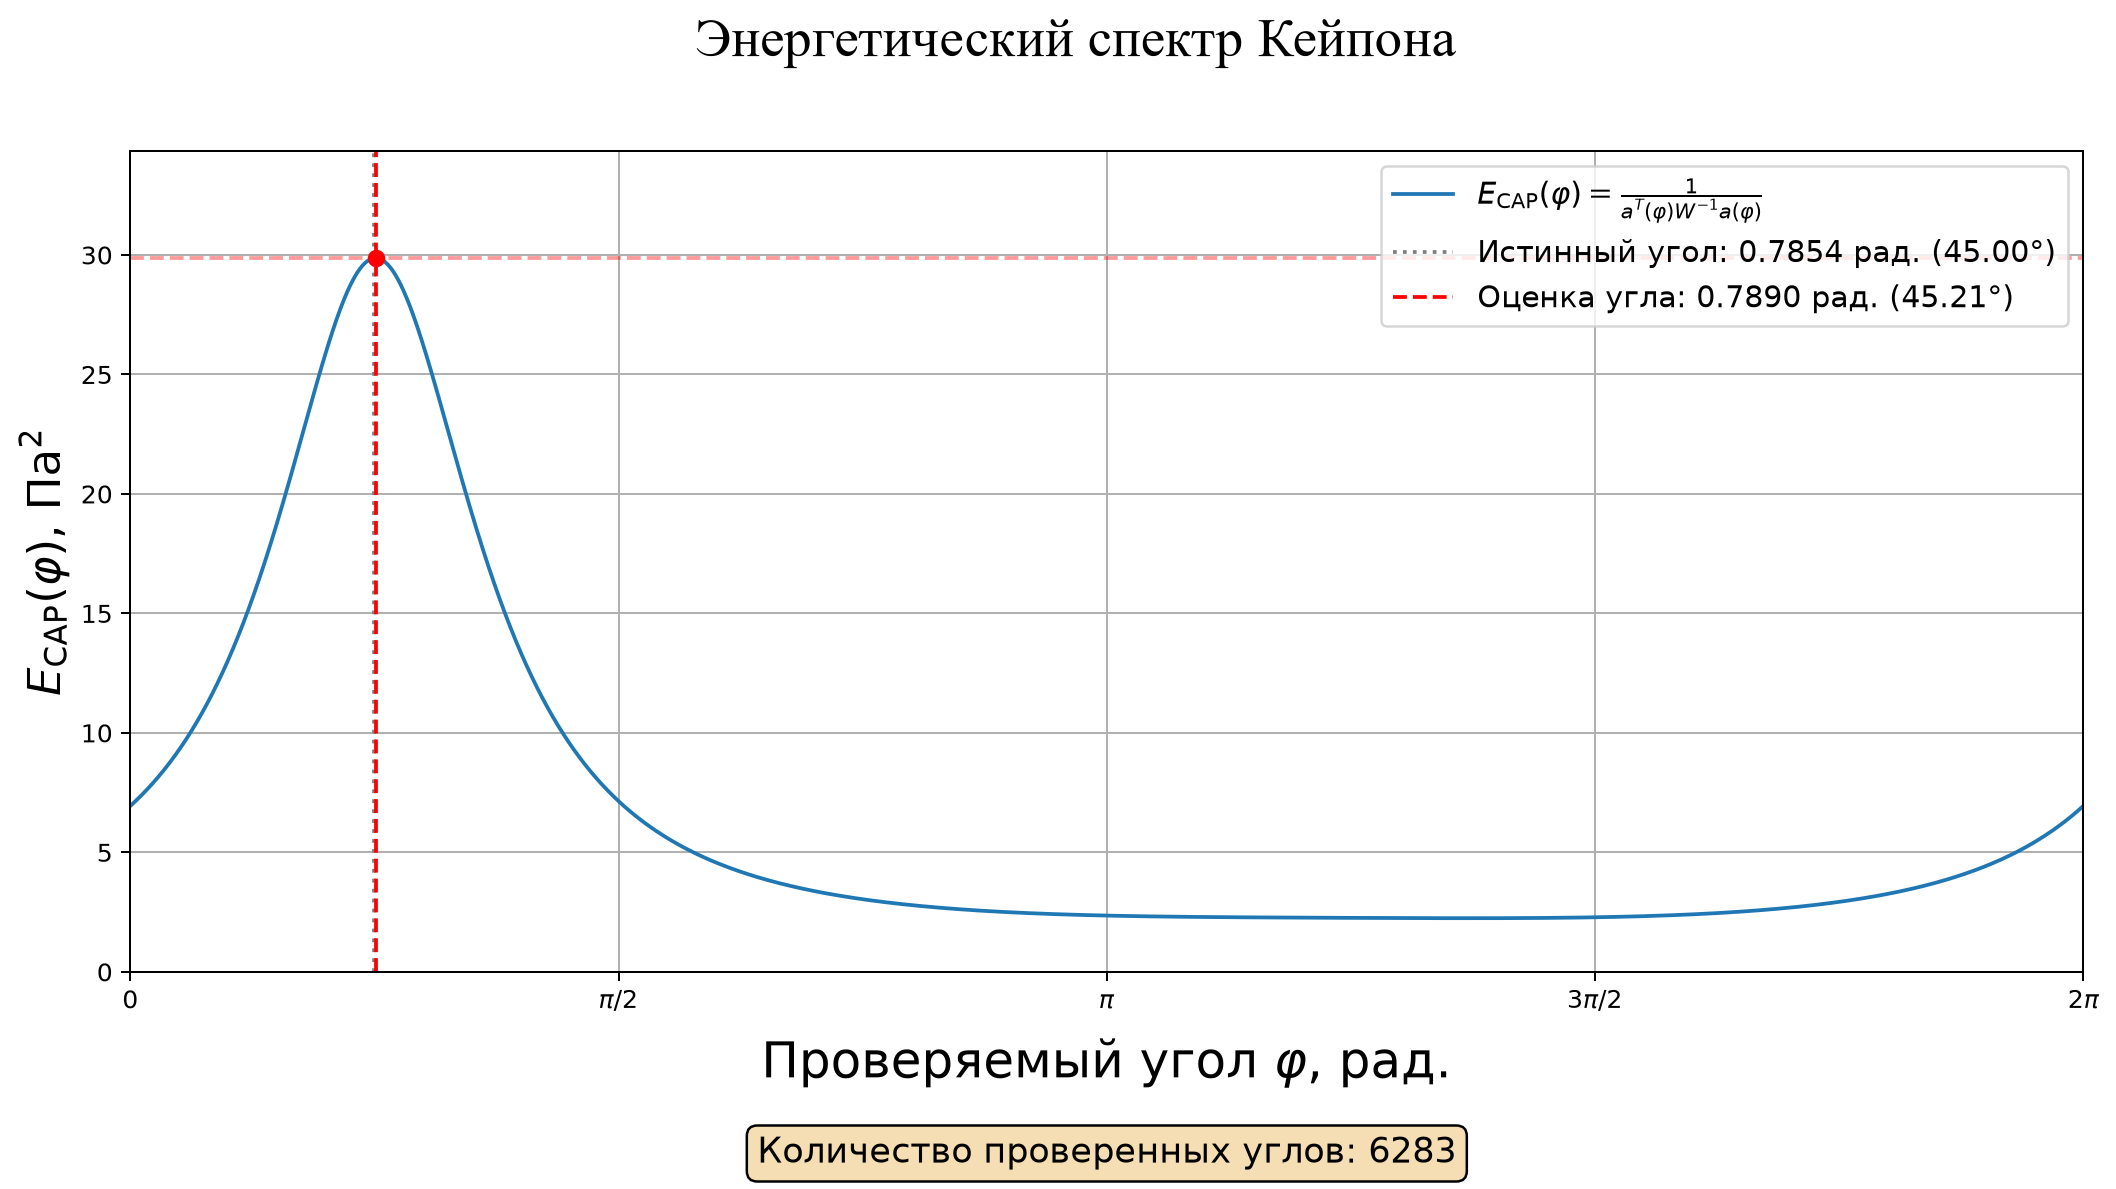

In [11]:

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_cap)
E_max = max(E_cap)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Кейпона и отметки углов
ax.plot(
    phi_vector, E_cap,
    label=r"$E_{\mathrm{CAP}}(\varphi)=\frac{1}{a^T(\varphi)W^{-1}a(\varphi)}$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.4f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Энергетический спектр Кейпона",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)

fig.savefig(FIG / '07_capon_original.png', dpi=180, bbox_inches='tight')
display(Image(filename=str(FIG/'07_capon_original.png')))
plt.close(fig)

## Аналитическая энергия и спектр; проверки нормировки

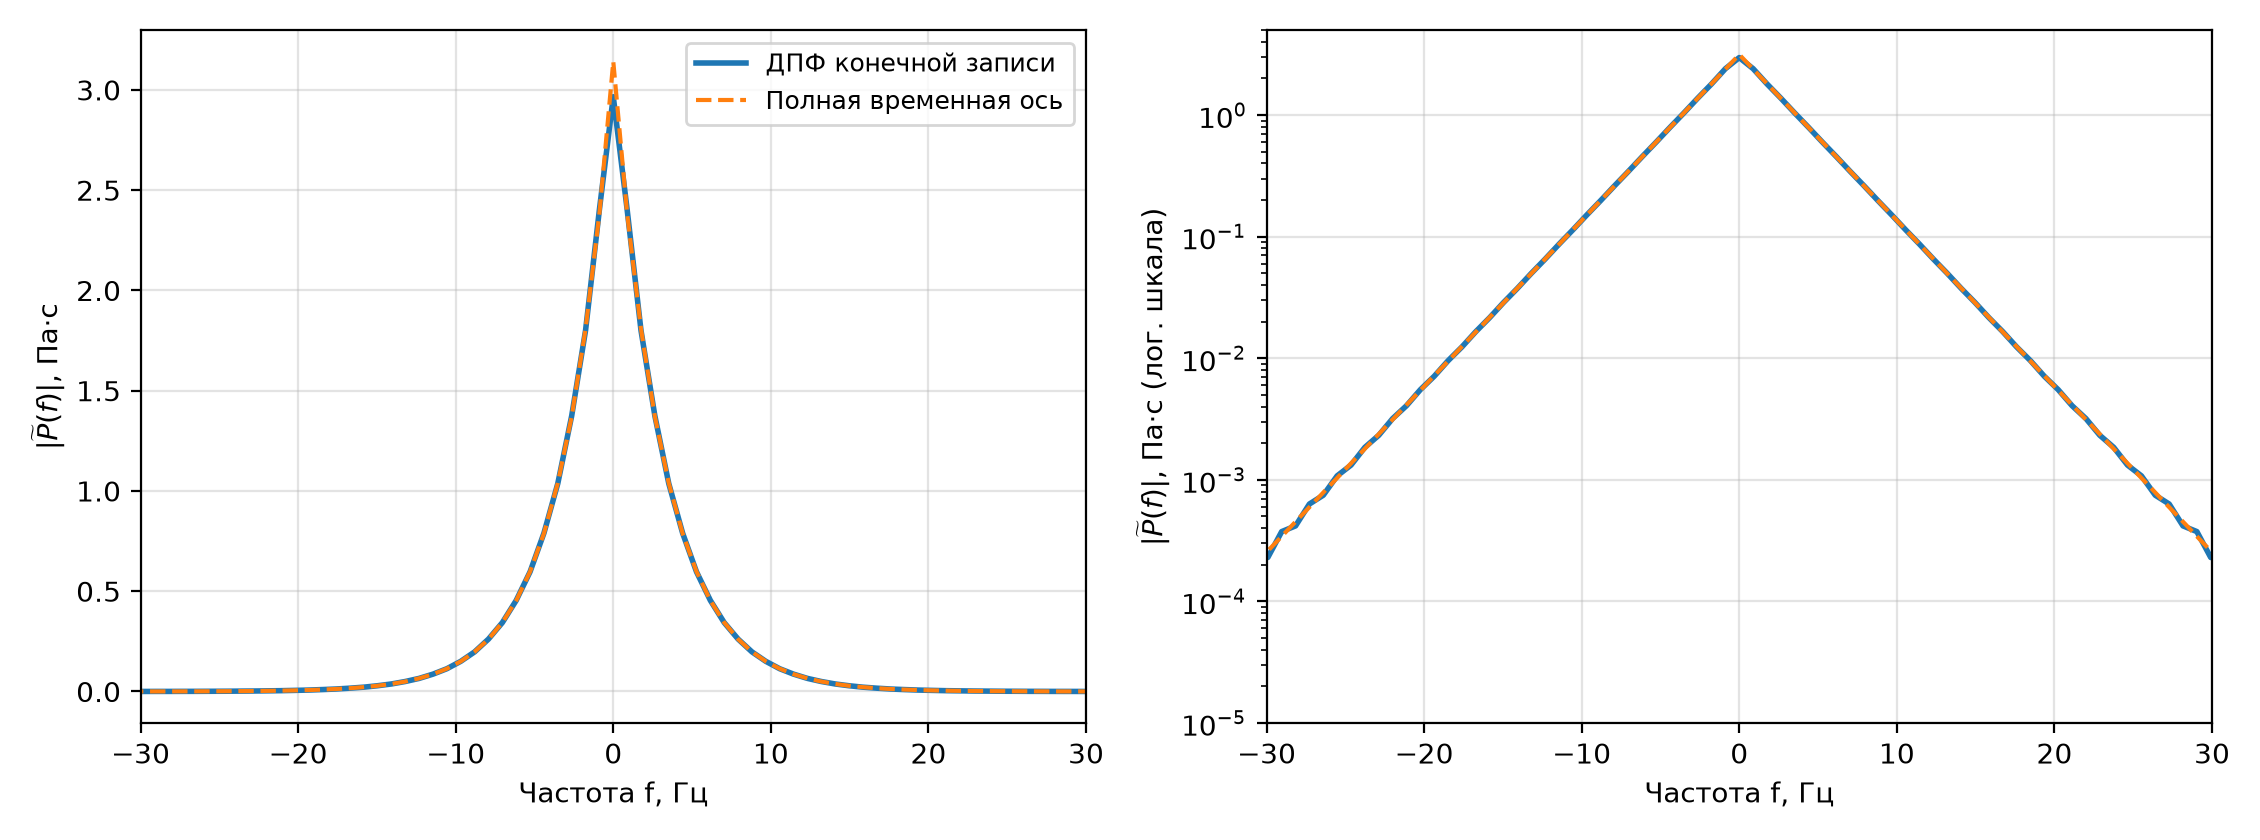

{
  "T": 1.13625,
  "tc": 0.568125,
  "tau": 0.05,
  "A": 1,
  "peak": 20.0,
  "E_imp_numeric": 31.40692129962366,
  "E_imp_analytic": 31.406921299978983,
  "E_infinite": 31.41592653589793,
  "nu": 0.9997133544379582,
  "E_sin": 0.5720548202597275,
  "sigma_imp": 3.7175835450700863,
  "sigma_sin": 0.5017263136847264,
  "fft_zero": 2.9660448695130373,
  "area_exact": 2.966027402449173,
  "fft_df": 0.88,
  "angular_step": 0.0010000294934234578,
  "delays": [
    0.003535533905932738,
    0.0012940952255126048,
    -0.004829629131445342
  ],
  "energies_channels": [
    31.40691923576906,
    31.4069210231423,
    31.406917448102007
  ],
  "energy_relative_error": 1.1313505687837733e-11,
  "f_99_energy": 7.329355988794278,
  "low_frequency_alpha_at_f99": 13.643763538418412
}


In [12]:

T = config_parametrs['duration_all']
tau = config_parametrs['duration_pulse']
A = config_parametrs['A']
tc = config_parametrs['center_pulse']
def primitive(x):
    return A*A/2 * (x/(x*x+tau*tau) + np.arctan(x/tau)/tau)
E_analytic = primitive(T-tc)-primitive(-tc)
E_infinite = np.pi*A*A/(2*tau)
nu = E_analytic/E_infinite
E_sin = calculate_energy(sin_signal, config_parametrs['time_vector'])
sigma_imp = calculate_noise_level(en_signal, config_parametrs['snr'], T)
sigma_sin = calculate_noise_level(E_sin, config_parametrs['snr'], T)
assert np.isclose(en_signal,E_analytic,rtol=1e-8)
assert np.isclose(sigma_imp**2*T*config_parametrs['snr'],en_signal)
f = cfg.FREQ_VECTOR
F_infinite = np.pi*A*np.exp(-2*np.pi*tau*np.abs(f))
fig, axs = plt.subplots(1,2,figsize=(11.3,4.2))
for ax in axs:
    ax.plot(f,freq_signal,label='ДПФ конечной записи',lw=2)
    ax.plot(f,F_infinite,'--',label='Полная временная ось',lw=1.5)
    ax.set_xlim(-30,30); ax.set_xlabel('Частота f, Гц'); ax.grid(True,alpha=.35)
axs[0].set_ylabel(r'$|\widetilde P(f)|$, Па·с')
axs[1].set_yscale('log'); axs[1].set_ylim(1e-5,5)
axs[1].set_ylabel(r'$|\widetilde P(f)|$, Па·с (лог. шкала)')
axs[0].legend(fontsize=9)
fig.tight_layout(); fig.savefig(FIG/'08_spectrum_comparison.png',dpi=200)
display(Image(filename=str(FIG/'08_spectrum_comparison.png'))); plt.close(fig)
assert np.allclose(pulse_signal,pulse_signal[::-1])
tau_array = get_tau_array(config_parametrs)
energies_channels = []
for delay in tau_array:
    cp = config_parametrs.copy(); cp['time_vector'] = config_parametrs['time_vector']-delay
    energies_channels.append(calculate_energy(get_impulse_signal(cp),cp['time_vector']))
checks = dict(T=T,tc=tc,tau=tau,A=A,peak=A/tau,E_imp_numeric=en_signal,
              E_imp_analytic=E_analytic,E_infinite=E_infinite,nu=nu,
              E_sin=E_sin,sigma_imp=sigma_imp,sigma_sin=sigma_sin,
              fft_zero=float(freq_signal[np.argmin(np.abs(f))]),
              area_exact=float(2*A*np.arctan(T/(2*tau))),
              fft_df=cfg.FS/cfg.N,angular_step=2*np.pi/len(cfg.PHI_VECTOR),
              delays=tau_array.tolist(),energies_channels=energies_channels,
              energy_relative_error=abs(en_signal/E_analytic-1),
              f_99_energy=np.log(100)/(4*np.pi*tau),
              low_frequency_alpha_at_f99=cfg.SPEED_ON_SOUND/(2*cfg.R*(np.log(100)/(4*np.pi*tau))))
print(json.dumps(checks,ensure_ascii=False,indent=2))


## Сравнение методов на одной реализации
Для каждого типа сигнала генератор заново инициализируется seed = 10.
Бартлетт и Кейпон работают с одной и той же матрицей наблюдений.
Для обоих сигналов задан энергетический SNR = 2.


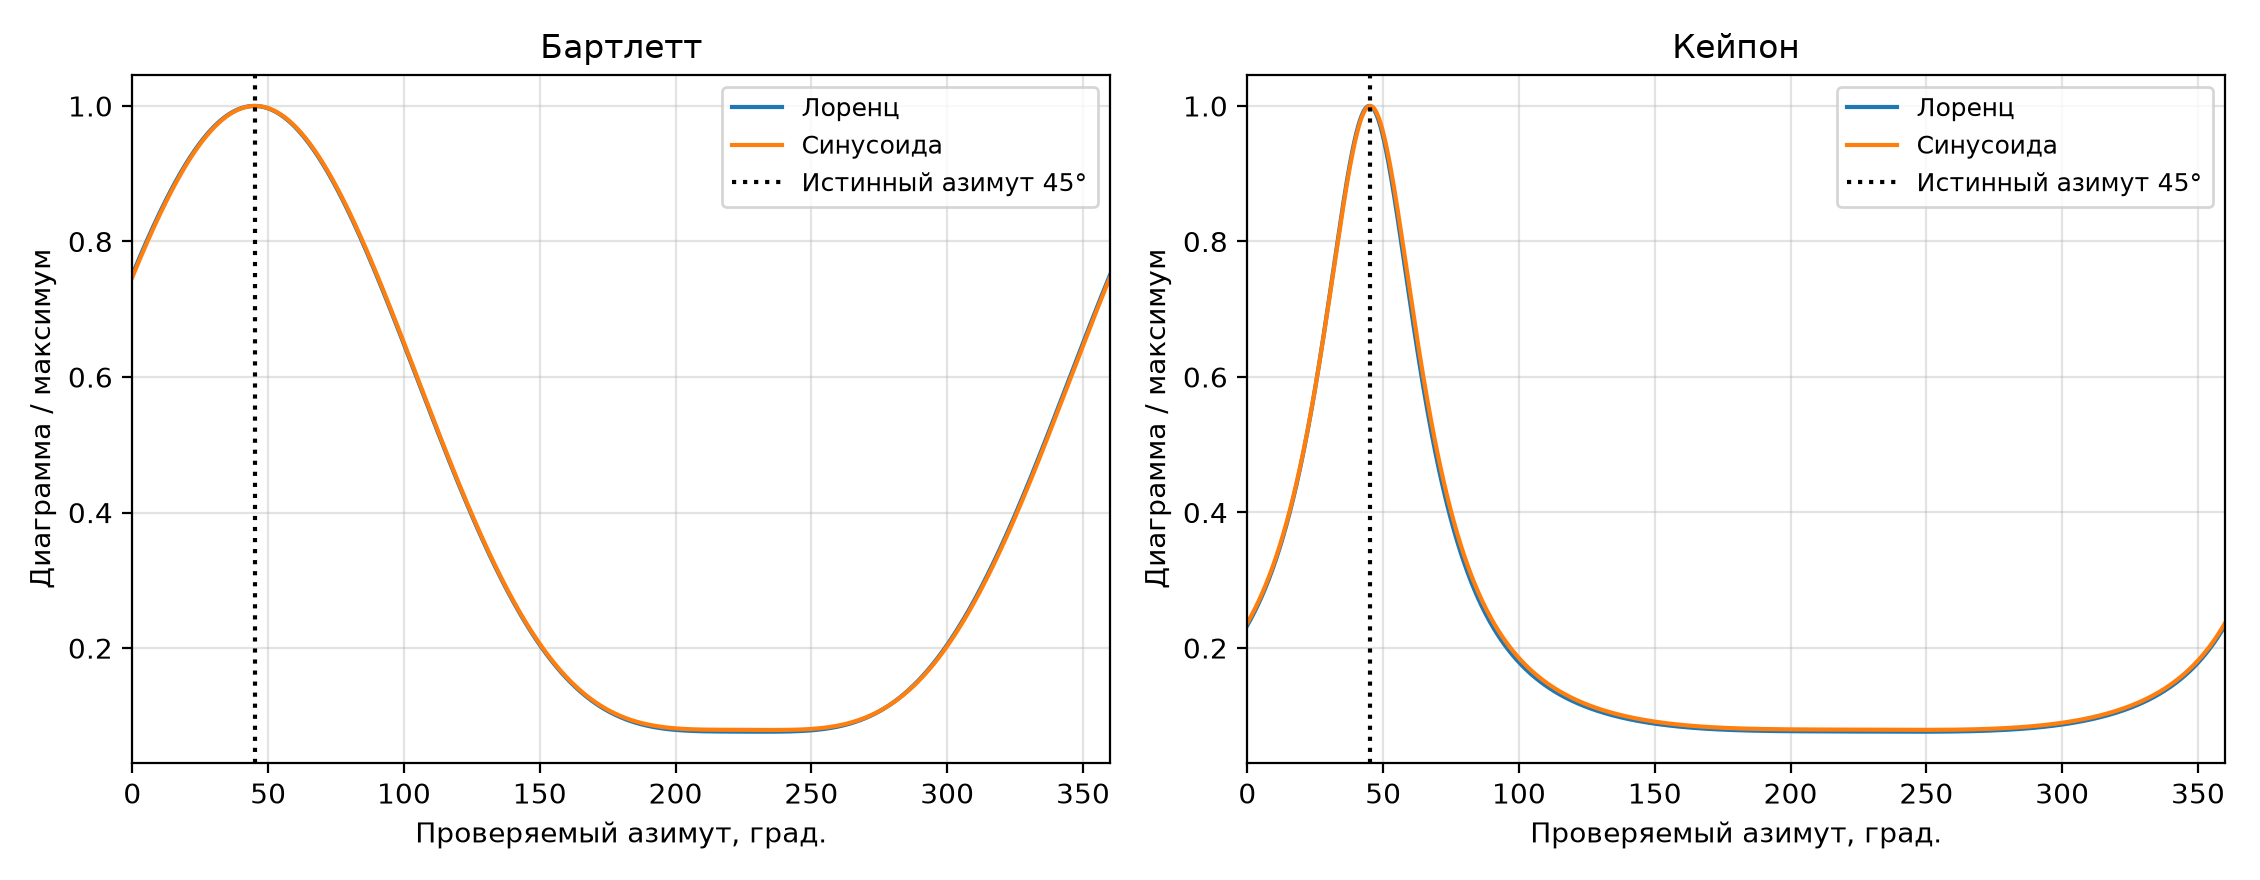

[{'signal': 'Лоренц', 'method': 'Бартлетт', 'estimate_deg': 44.92121597962756, 'error_deg': -0.07878402037244102}, {'signal': 'Лоренц', 'method': 'Кейпон', 'estimate_deg': 44.92121597962756, 'error_deg': -0.07878402037244102}, {'signal': 'Синусоида', 'method': 'Бартлетт', 'estimate_deg': 45.20770332643641, 'error_deg': 0.2077033264363961}, {'signal': 'Синусоида', 'method': 'Кейпон', 'estimate_deg': 45.20770332643641, 'error_deg': 0.2077033264363961}]


In [13]:

from py_files.experiment_stats import list_errors, calculate_variance, var_vs_params
methods = {'Бартлетт':get_barlet_values,'Кейпон':get_cap_values}
signals_to_compare = {'Лоренц':get_impulse_signal,'Синусоида':get_sin_signal}
single_results = []
fig, axs = plt.subplots(1,2,figsize=(11.3,4.4))
for signal_name, signal_func in signals_to_compare.items():
    cp = cfg.init_rng(10)
    X = get_channel_matrix(cp,get_tau_array(cp),signal_func)
    W0 = get_covariation_matrix(X,cp['N'])
    D = get_direction_matrix(cp['phis'],cp['M'])
    for ax,(method,func) in zip(axs,methods.items()):
        val = func(W0,D)
        estimate = get_est_phi(cp['phis'],val)
        error = (estimate-cp['target_phi']+np.pi)%(2*np.pi)-np.pi
        single_results.append(dict(signal=signal_name,method=method,estimate_deg=float(np.degrees(estimate)),error_deg=float(np.degrees(error))))
        ax.plot(np.degrees(cp['phis']),val/np.max(val),label=signal_name)
        ax.set_title(method); ax.set_xlabel('Проверяемый азимут, град.'); ax.grid(True,alpha=.35)
        ax.set_xlim(0,360)
for ax in axs:
    ax.axvline(45,color='black',ls=':',label='Истинный азимут 45°')
    ax.legend(fontsize=9); ax.set_ylabel('Диаграмма / максимум')
fig.tight_layout(); fig.savefig(FIG/'09_direction_comparison.png',dpi=200)
display(Image(filename=str(FIG/'09_direction_comparison.png'))); plt.close(fig)
print(single_results)


## Дисперсия ошибки в зависимости от SNR
Схема соответствует ячейке 3 `report.ipynb`: `var_vs_params` →
`list_errors` → `single_est`. Здесь `list_errors` вызывается явно, чтобы
сохранить индивидуальные ошибки и дополнительно вычислить смещение и RMSE.
Сетка SNR исходной ячейки 0,1…1 дополнена базовой точкой SNR = 2.
На каждую точку и метод приходится 100 реализаций, как в конфигурации.
Генераторы методов независимы как объекты, но инициализируются одинаково,
что обеспечивает сравнение на одинаковых стандартизованных шумах.


Лоренц Бартлетт готово


Лоренц Кейпон готово


Синусоида Бартлетт готово


Синусоида Кейпон готово


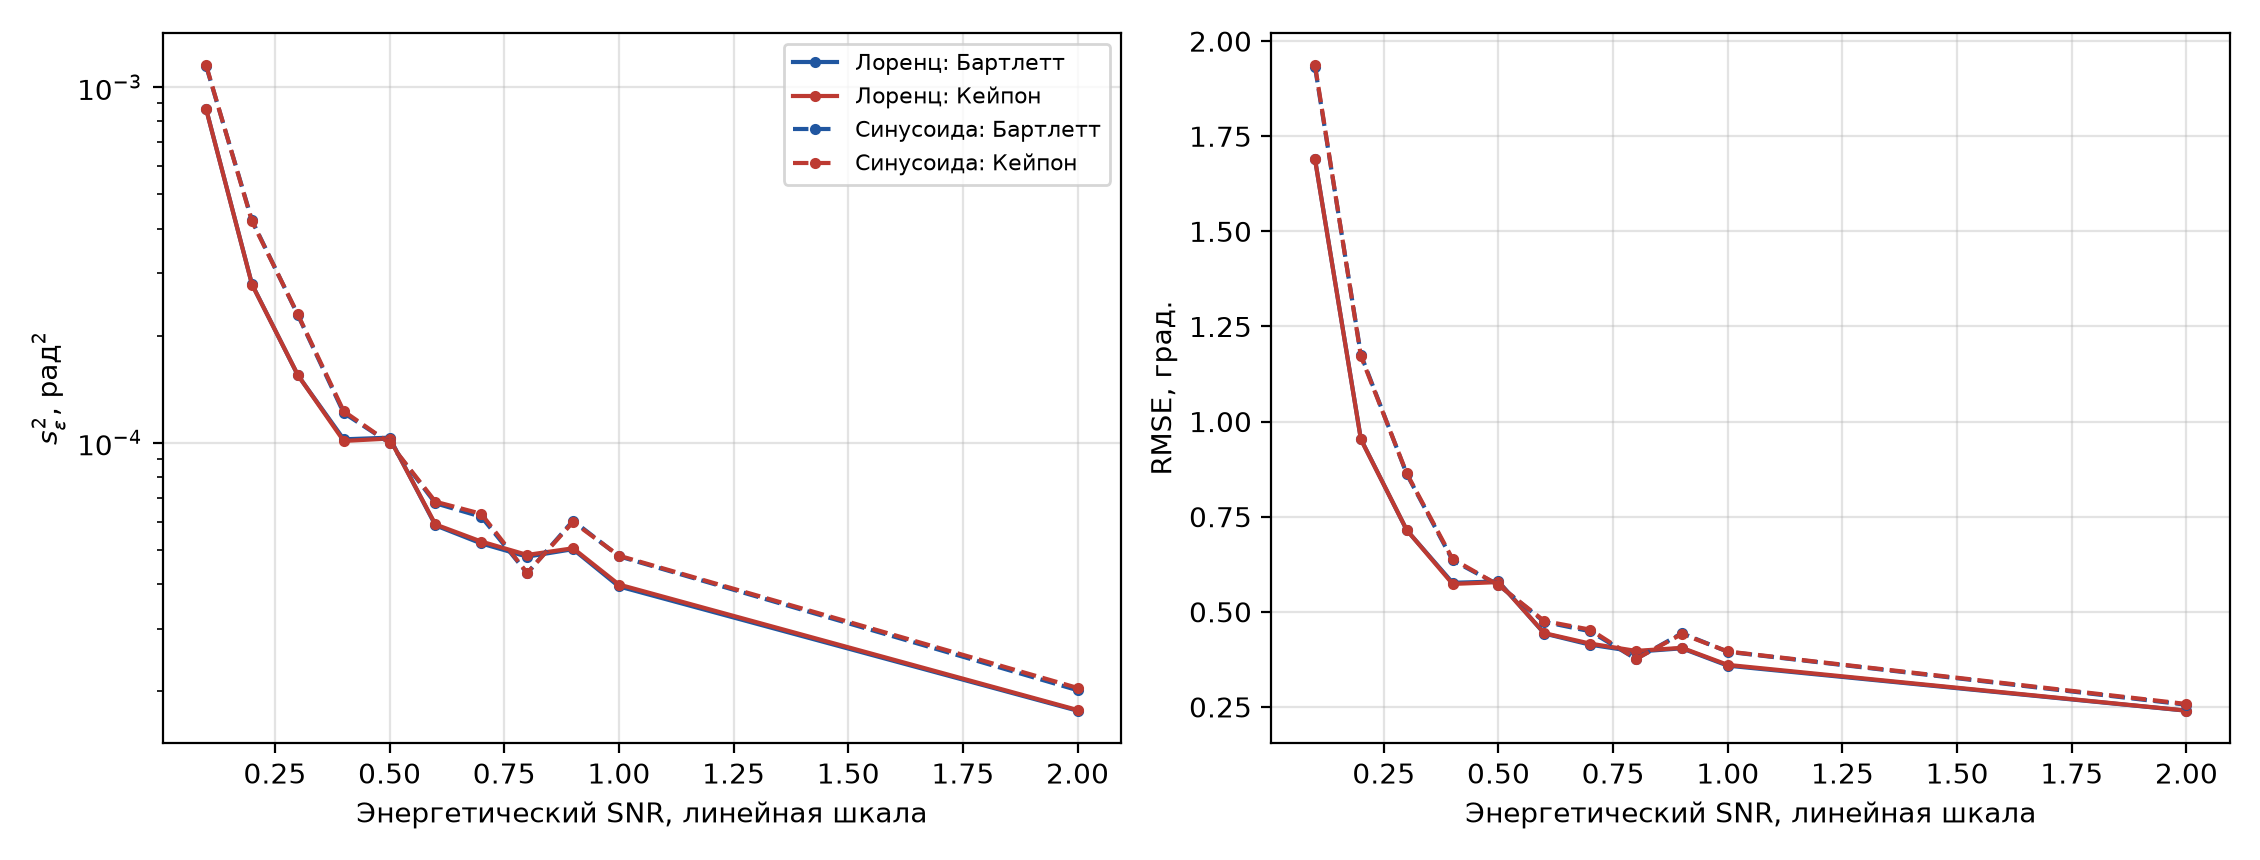

12077

In [14]:

SNR_VALUES = np.r_[np.linspace(0.1,1,10),cfg.SNR]
rows = []; raw_errors = {}
for signal_name, signal_func in signals_to_compare.items():
    for method,func in methods.items():
        cp = cfg.init_rng(10)
        for snr in SNR_VALUES:
            cp['snr'] = float(snr)
            errors = np.asarray(list_errors(cp,func,signal_func))
            key = f'{signal_name}|{method}|{snr:.12g}'
            raw_errors[key] = errors.tolist()
            rows.append(dict(signal=signal_name,method=method,snr=float(snr),K=len(errors),
                             bias_rad=float(np.mean(errors)),variance_rad2=float(calculate_variance(errors)),
                             rmse_rad=float(np.sqrt(np.mean(errors**2)))))
        print(signal_name,method,'готово')
with (OUT/'statistics.csv').open('w',encoding='utf-8-sig',newline='') as fp:
    writer=csv.DictWriter(fp,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
(OUT/'errors.json').write_text(json.dumps(raw_errors,ensure_ascii=False,indent=2),encoding='utf-8')
# Verify the explicitly expanded loop against the original notebook's helper.
cp = cfg.init_rng(10)
expected = var_vs_params(cp,get_barlet_values,get_impulse_signal,'snr',SNR_VALUES[:2])
actual = [r['variance_rad2'] for r in rows if r['signal']=='Лоренц' and r['method']=='Бартлетт'][:2]
assert np.array_equal(expected,actual)
fig,axs=plt.subplots(1,2,figsize=(11.3,4.3))
styles = {'Лоренц':'-','Синусоида':'--'}
colors = {'Бартлетт':'#2056a0','Кейпон':'#bd3a32'}
for signal_name in signals_to_compare:
    for method in methods:
        data=[r for r in rows if r['signal']==signal_name and r['method']==method]
        x=[r['snr'] for r in data]
        axs[0].plot(x,[r['variance_rad2'] for r in data],styles[signal_name],color=colors[method],marker='.',label=f'{signal_name}: {method}')
        axs[1].plot(x,np.degrees([r['rmse_rad'] for r in data]),styles[signal_name],color=colors[method],marker='.')
for ax in axs:
    ax.set_xlabel('Энергетический SNR, линейная шкала');ax.grid(True,alpha=.35)
axs[0].set_ylabel(r'$s_\varepsilon^2$, рад$^2$');axs[0].set_yscale('log')
axs[1].set_ylabel('RMSE, град.');axs[0].legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG/'10_statistics_comparison.png',dpi=200)
display(Image(filename=str(FIG/'10_statistics_comparison.png')));plt.close(fig)
summary=dict(checks=checks,single=single_results,statistics=rows,
             parameters={k:config_parametrs[k] for k in ['M','N','fs','R','c','f0','snr','main_seed','realisation_count','alpha','target_phi']},
             versions=dict(python=sys.version,numpy=np.__version__,matplotlib=matplotlib.__version__))
(OUT/'results.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
